# 1. Environment Setup

## 1.1 Libarary Imports

In [99]:
%pip install urllib3 xarray numpy pandas tqdm pillow matplotlib plotly seaborn scikit-learn tensorflow keras-tuner netCDF4 h5netcdf


[notice] A new release of pip is available: 25.0 -> 25.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [100]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


## 1.2 Import Data

In [101]:
data_folder = "monthly_precipitation_maps"

# Load the CSV file containing the date and value columns
df = pd.read_csv("monthly_precipitation.csv")
# Ensure the date is a string for matching purposes
df['Date'] = df['Date'].astype(str)

# Create a dictionary for quick lookup: key = date (YYYYMM), value = precipitation value
value_dict = dict(zip(df['Date'], df['Value']))

# List all png files with the expected naming pattern
image_files = glob.glob(os.path.join(data_folder, "precipitation_plot_*.png"))

# Prepare lists to hold images and corresponding labels
X = []
y = []

# Define a regex pattern to extract date info from filename, e.g., precipitation_plot_2010-01.png
date_pattern = re.compile(r'precipitation_plot_(\d{4})-(\d{2})\.png')

# Target image size for the CNN
IMG_SIZE = (350, 500)

for file in image_files:
    match = date_pattern.search(os.path.basename(file))
    if match:
        year, month = match.groups()
        # Convert to YYYYMM format to match CSV date column
        date_key = year + month  
        # Only load image if the date exists in the CSV data
        if date_key in value_dict:
            # Load and resize the image
            img = load_img(file, target_size=IMG_SIZE)
            img_array = img_to_array(img)
            X.append(img_array)
            y.append(value_dict[date_key])
            
# Convert lists to numpy arrays and normalize image data
X = np.array(X, dtype="float32") / 255.0
y = np.array(y, dtype="float32")

print("Total samples loaded:", X.shape[0])

Total samples loaded: 72


## 1.3 Visualize Data

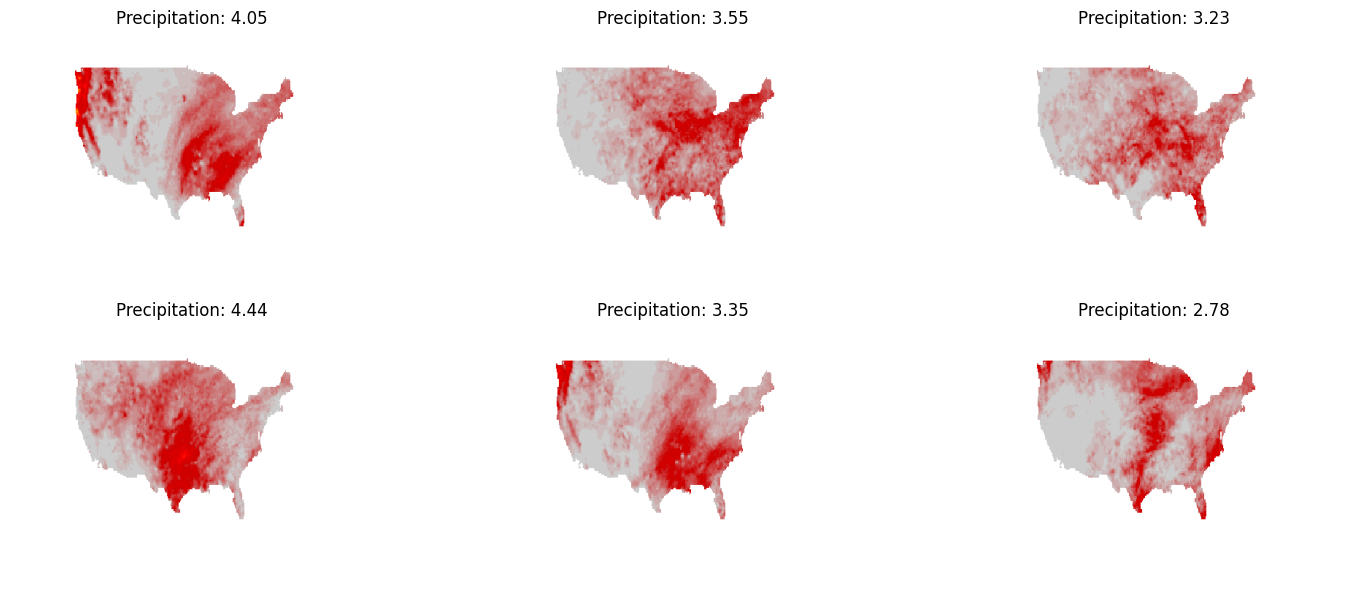

In [102]:
# Visualize a sampling of the plots along with their precipitation values
num_samples = 6
plt.figure(figsize=(15, 6))
for i in range(num_samples):
    plt.subplot(2, 3, i+1)
    plt.imshow(X[i])
    plt.title(f"Precipitation: {y[i]:.2f}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [103]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Train samples: 57
Test samples: 15


# 2. Model Development

## 2.1 Base CNN Model
- **Depth:** The network consists of 3 convolutional blocks followed by a flattening operation and 2 fully connected (dense) layers.
- **Width:** The convolutional layers expand in width: starting with 32 filters, then 64, and finally 128 filters, increasing the model's capacity to capture complex features.
- **Layer Composition:**
  - Convolutional Blocks: Each block applies a 3×3 convolution with ReLU activation to extract spatial features, immediately followed by a 2×2 max pooling layer that reduces spatial dimensions and controls overfitting.
  - Flattening: Converts the 2D feature maps into a 1D feature vector, bridging the convolutional and dense parts of the network.
  - Dense Layers: A hidden dense layer with 64 neurons (using ReLU) refines the extracted features, culminating in a single neuron output layer designed for regression.
- **Overall Function:** The model progressively transforms the raw image data into increasingly abstract representations, ultimately predicting a continuous value (e.g., precipitation) with a regression output.

In [104]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1)  # Single output for regression
])

model.compile(optimizer='adam', loss='mse')
model.summary()

/Users/xanderyoon/anaconda3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 348, 498, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 174, 249, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 172, 247, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 86, 123, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 84, 121, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 42, 60, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 322560)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │    20,643,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,737,217 (79.11 MB)

 Trainable params: 20,737,217 (79.11 MB)

 Non-trainable params: 0 (0.00 B)

## 2.2 Model Evaluation

We visualize the model's loss and performance over epoch's to gain a better understanding of how we can improve the model's design. 

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 961ms/step - loss: 90.6428 - val_loss: 28.4425
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 880ms/step - loss: 20.0622 - val_loss: 7.2909
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 864ms/step - loss: 4.8186 - val_loss: 2.6317
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 896ms/step - loss: 2.1715 - val_loss: 1.8629
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - loss: 1.1442 - val_loss: 0.3388
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - loss: 0.7679 - val_loss: 0.3339
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 986ms/step - loss: 0.5059 - val_loss: 0.8033
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 872ms/step - loss: 0.4369 - val_loss: 0.3457
Epoch 9/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 845ms/step - loss: 0.4166 - val_loss: 0.4974
Epoch 10/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 842ms/step - loss: 0.3067 - val_loss: 0.2200
Epoch 11/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 845ms/step - loss: 0.2129 - val_loss: 0.2245
Epoch 12/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 870ms/step - loss: 0.1145 - val_loss:

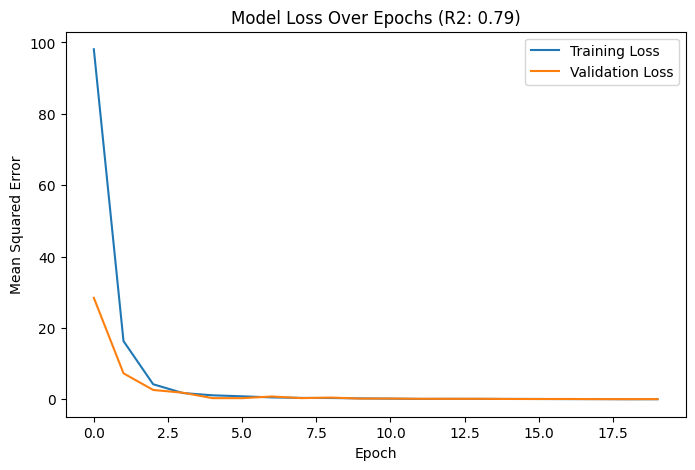

0.7894070523181751

In [ ]:
def plot_history_and_r2(history, model, X_test, y_test):
    """
    Plots the training and validation loss curves from the history object and computes the R2 score.
    
    Parameters:
        history: History object returned from model.fit()
        model: Trained Keras model
        X_test: Test set images
        y_test: True target values for the test set
        
    Returns:
        r2: The R2 score computed on the test set predictions
    """
    # Compute predictions on the test set and calculate the R2 score
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    
    # Plot training and validation loss curves
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Mean Squared Error')
    plt.title(f'Model Loss Over Epochs (R2: {r2:.2f})')
    plt.legend()
    plt.show()
    
    return r2

history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=20, batch_size=16)
plot_history_and_r2(history, model, X_test, y_test)


## 2.3 Model Architecture (Depth / Width)
- **Overfitting:**
  - What It Looks Like: The model performs exceptionally well on the training set but struggles on the validation/test set (high training accuracy, low validation accuracy).
  - Risk Factor: With more layers and filters, the model may learn noise or irrelevant details.
  - How to Mitigate: Use techniques like early stopping, dropout, regularization, or reduce model complexity.

- **Underfitting:**
  - What It Looks Like: The model has high errors on both training and validation sets (low training accuracy, low validation accuracy).
  - Reason: The model lacks sufficient complexity to learn the underlying patterns.
  - How to Address: Increase model depth/width or tune hyperparameters (e.g., learning rate, number of epochs).

- **When to Increase Model Depth/Width:**
  - If the model is underfitting and consistently failing to capture patterns.
  - If you have sufficient data and computational resources to support a more complex network.

- **When to Decrease Model Depth/Width:**
  - If the model overfits quickly or you observe diminishing returns on validation performance.
  - If training is excessively slow or you lack the data needed to train a large network effectively.

In [106]:
# Define a shallower model by reducing the number of convolutional blocks and dense units
shallow_model = Sequential([
    # First Convolutional Block
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    MaxPooling2D((2, 2)),
    
    # Second Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    # Flattening the feature maps and adding a small dense network for regression
    Flatten(),
    Dense(32, activation='relu'),
    Dense(1)  # Single output for regression
])

shallow_model.compile(optimizer='adam', loss='mse')
shallow_model.summary()


/Users/xanderyoon/anaconda3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_22 (Conv2D)              │ (None, 348, 498, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 174, 249, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 172, 247, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 86, 123, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 676992)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │    21,663,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,683,201 (82.71 MB)

 Trainable params: 21,683,201 (82.71 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 685ms/step - loss: 0.1418 - val_loss: 0.1931
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 610ms/step - loss: 0.1091 - val_loss: 0.1586
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 650ms/step - loss: 0.0889 - val_loss: 0.1313
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 615ms/step - loss: 0.0574 - val_loss: 0.1030
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 619ms/step - loss: 0.0682 - val_loss: 0.0968
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 648ms/step - loss: 0.0524 - val_loss: 0.0696
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 609ms/step - loss: 0.0364 - val_loss: 0.0674
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 614ms/step - loss: 0.0312 - val_loss: 0.0548
Epoch 9/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 607ms/step - loss: 0.0248 - val_loss: 0.0646
Epoch 10/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 611ms/step - loss: 0.0222 - val_loss: 0.0478
Epoch 11/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 619ms/step - loss: 0.0230 - val_loss: 0.0614
Epoch 12/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 640ms/step - loss: 0.0186 - val_lo

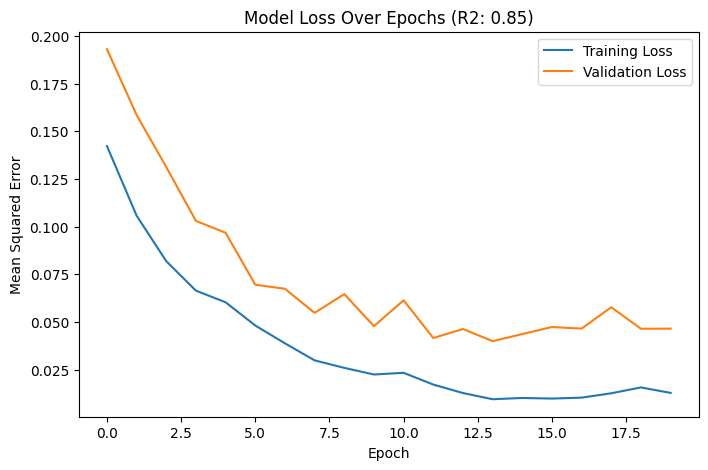

0.8530593251502033

In [108]:
history = shallow_model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=20, batch_size=16)
plot_history_and_r2(history, shallow_model, X_test, y_test)

# 3. Hyperparameter Tuning

- **Hyperparameter Tuning:** 
  - Helps find optimal values for parameters like the number of filters, kernel sizes, dense layer units, or learning rate. 
  - This systematic search can significantly improve model performance without manually guessing parameter values.
- **Early Stopping:** 
  - Monitors validation loss (or another metric) during training and stops once the metric stops improving. 
  - Prevents overfitting by halting training at the optimal point and restoring the best model weights.